In [1]:
import os
import sys
sys.path.append('..')
import logging
logging.basicConfig(level=logging.WARN)

In [2]:
from qunoc.element.benchmark import *

vqe_program = VQE(5)
print(f"VQE program: {vqe_program}")
qft_program = QFT(5)
print(f"QFT program: {qft_program}")
qaoa_program = QAOA(5)
print(f"QAOA program: {qaoa_program}")
bv_program = BV(5)
print(f"BV program: {bv_program}")

VQE program: Control_0_1, Control_0_2, Control_0_3, Control_0_4, Control_1_2, Control_1_3, Control_1_4, Control_2_3, Control_2_4, Control_3_4
QFT program: Control_1_0, Control_2_0, Control_3_0, Control_2_1, Control_4_0, Control_3_1, Control_4_1, Control_3_2, Control_4_2, Control_4_3
QAOA program: Control_1_4, Control_0_2, Control_1_3, Control_0_4, Control_2_4
BV program: Control_0_1, Control_0_3


In [ ]:
from qunoc.utils.utils import get_timestamp
from qunoc.element.package import *

result_dir = f"result/layout/greedy/example_{get_timestamp()}/"
os.makedirs(result_dir, exist_ok=True)

package = Package(design_strategy="greedy", result_dir=result_dir)
# package = Package((50, 50), FabricateModel(10, 10), design_strategy="greedy", result_dir=result_dir)
print("Package score: ", package.estimate_efficiency())
package.draw_chiplets()

Initial score:  0.6893138101097777
New action:  (ComputeModule_0_0_99_99, Grid, Y, 11)
New score:  2.162835464997075
New action:  (ComputeModule_84_84_99_99, Grid, X, 1)
New score:  2.273672830999545


2025-04-17 19:30:37.562086: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-04-17 19:30:37.574911: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-04-17 19:30:37.588350: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-04-17 19:30:37.592378: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-04-17 19:30:37.604063: I tensorflow/core/platform/cpu_feature_guar

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Training agent...
----------------------------------
| rollout/           |           |
|    ep_len_mean     | 216       |
|    ep_rew_mean     | -2.03e+10 |
| time/              |           |
|    fps             | 5         |
|    iterations      | 1         |
|    time_elapsed    | 372       |
|    total_timesteps | 2048      |
----------------------------------
-------------------------------------------
| rollout/                |               |
|    ep_len_mean          | 278           |
|    ep_rew_mean          | -2.62e+10     |
| time/                   |               |
|    fps                  | 5             |
|    iterations           | 2             |
|    time_elapsed         | 687           |
|    total_timesteps      | 4096          |
| train/                  |               |
|    approx_kl            | 0.00010108881 |
|    clip_fraction        | 0             |
|    clip

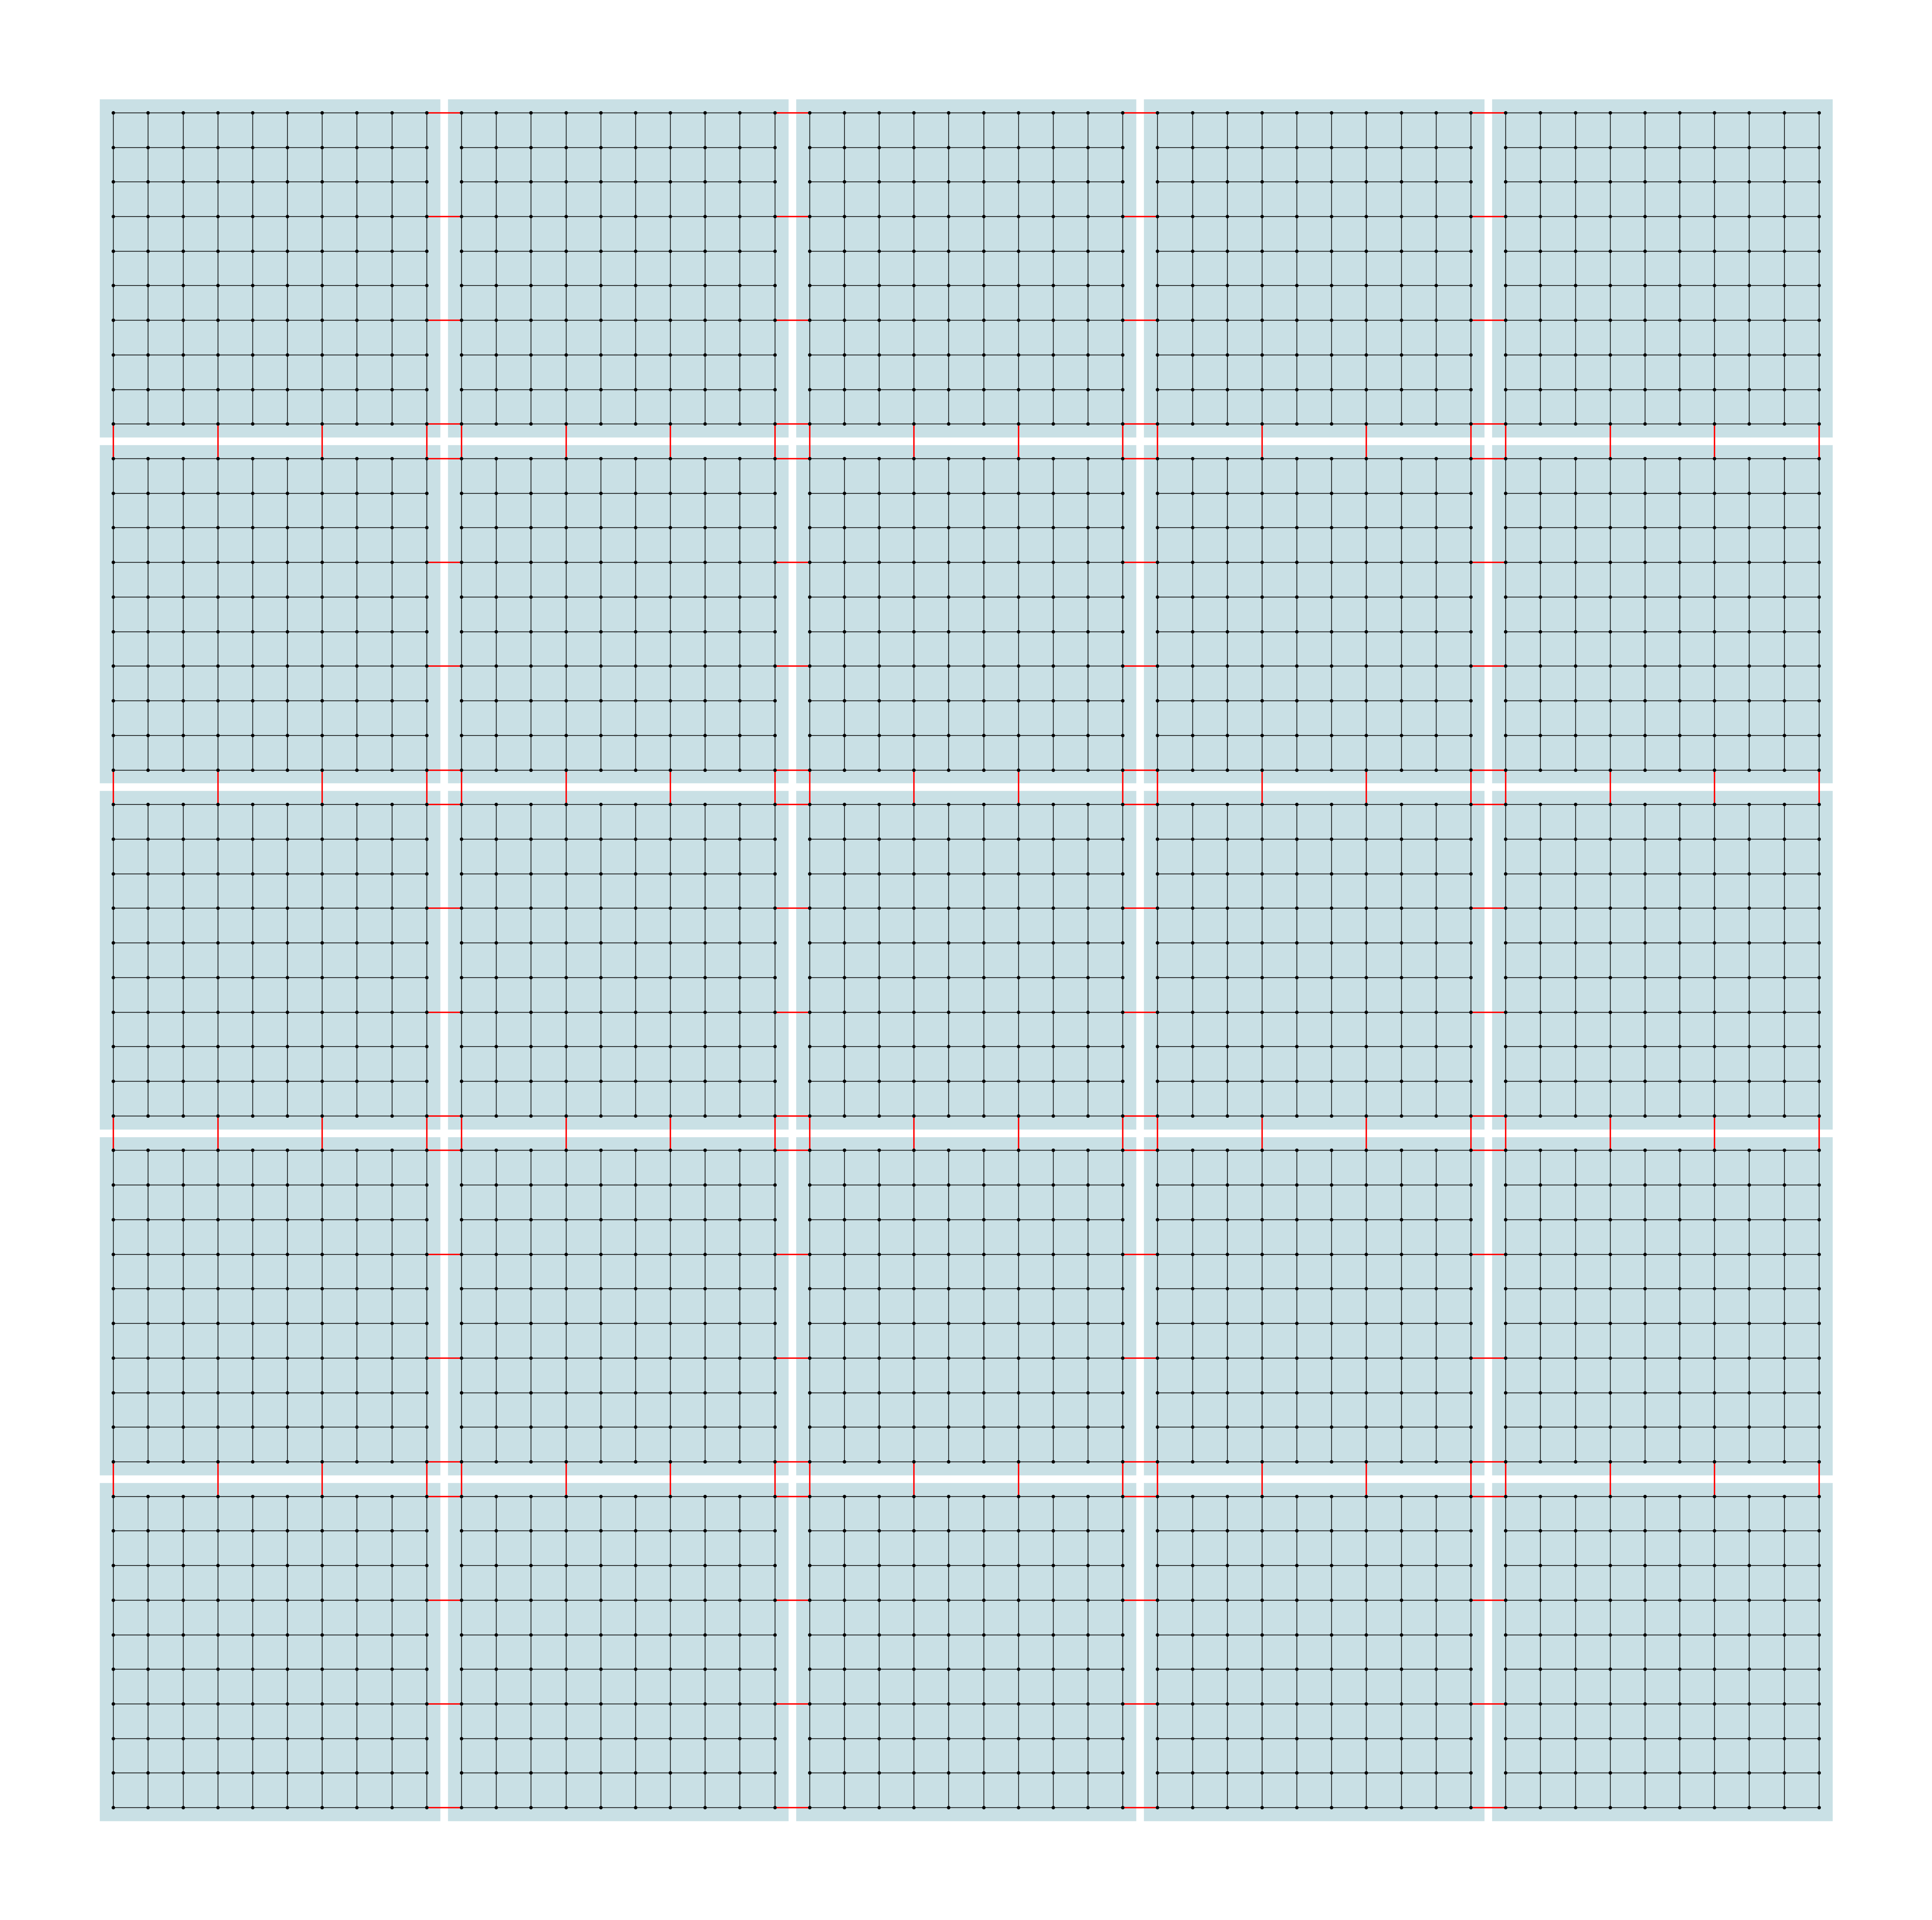

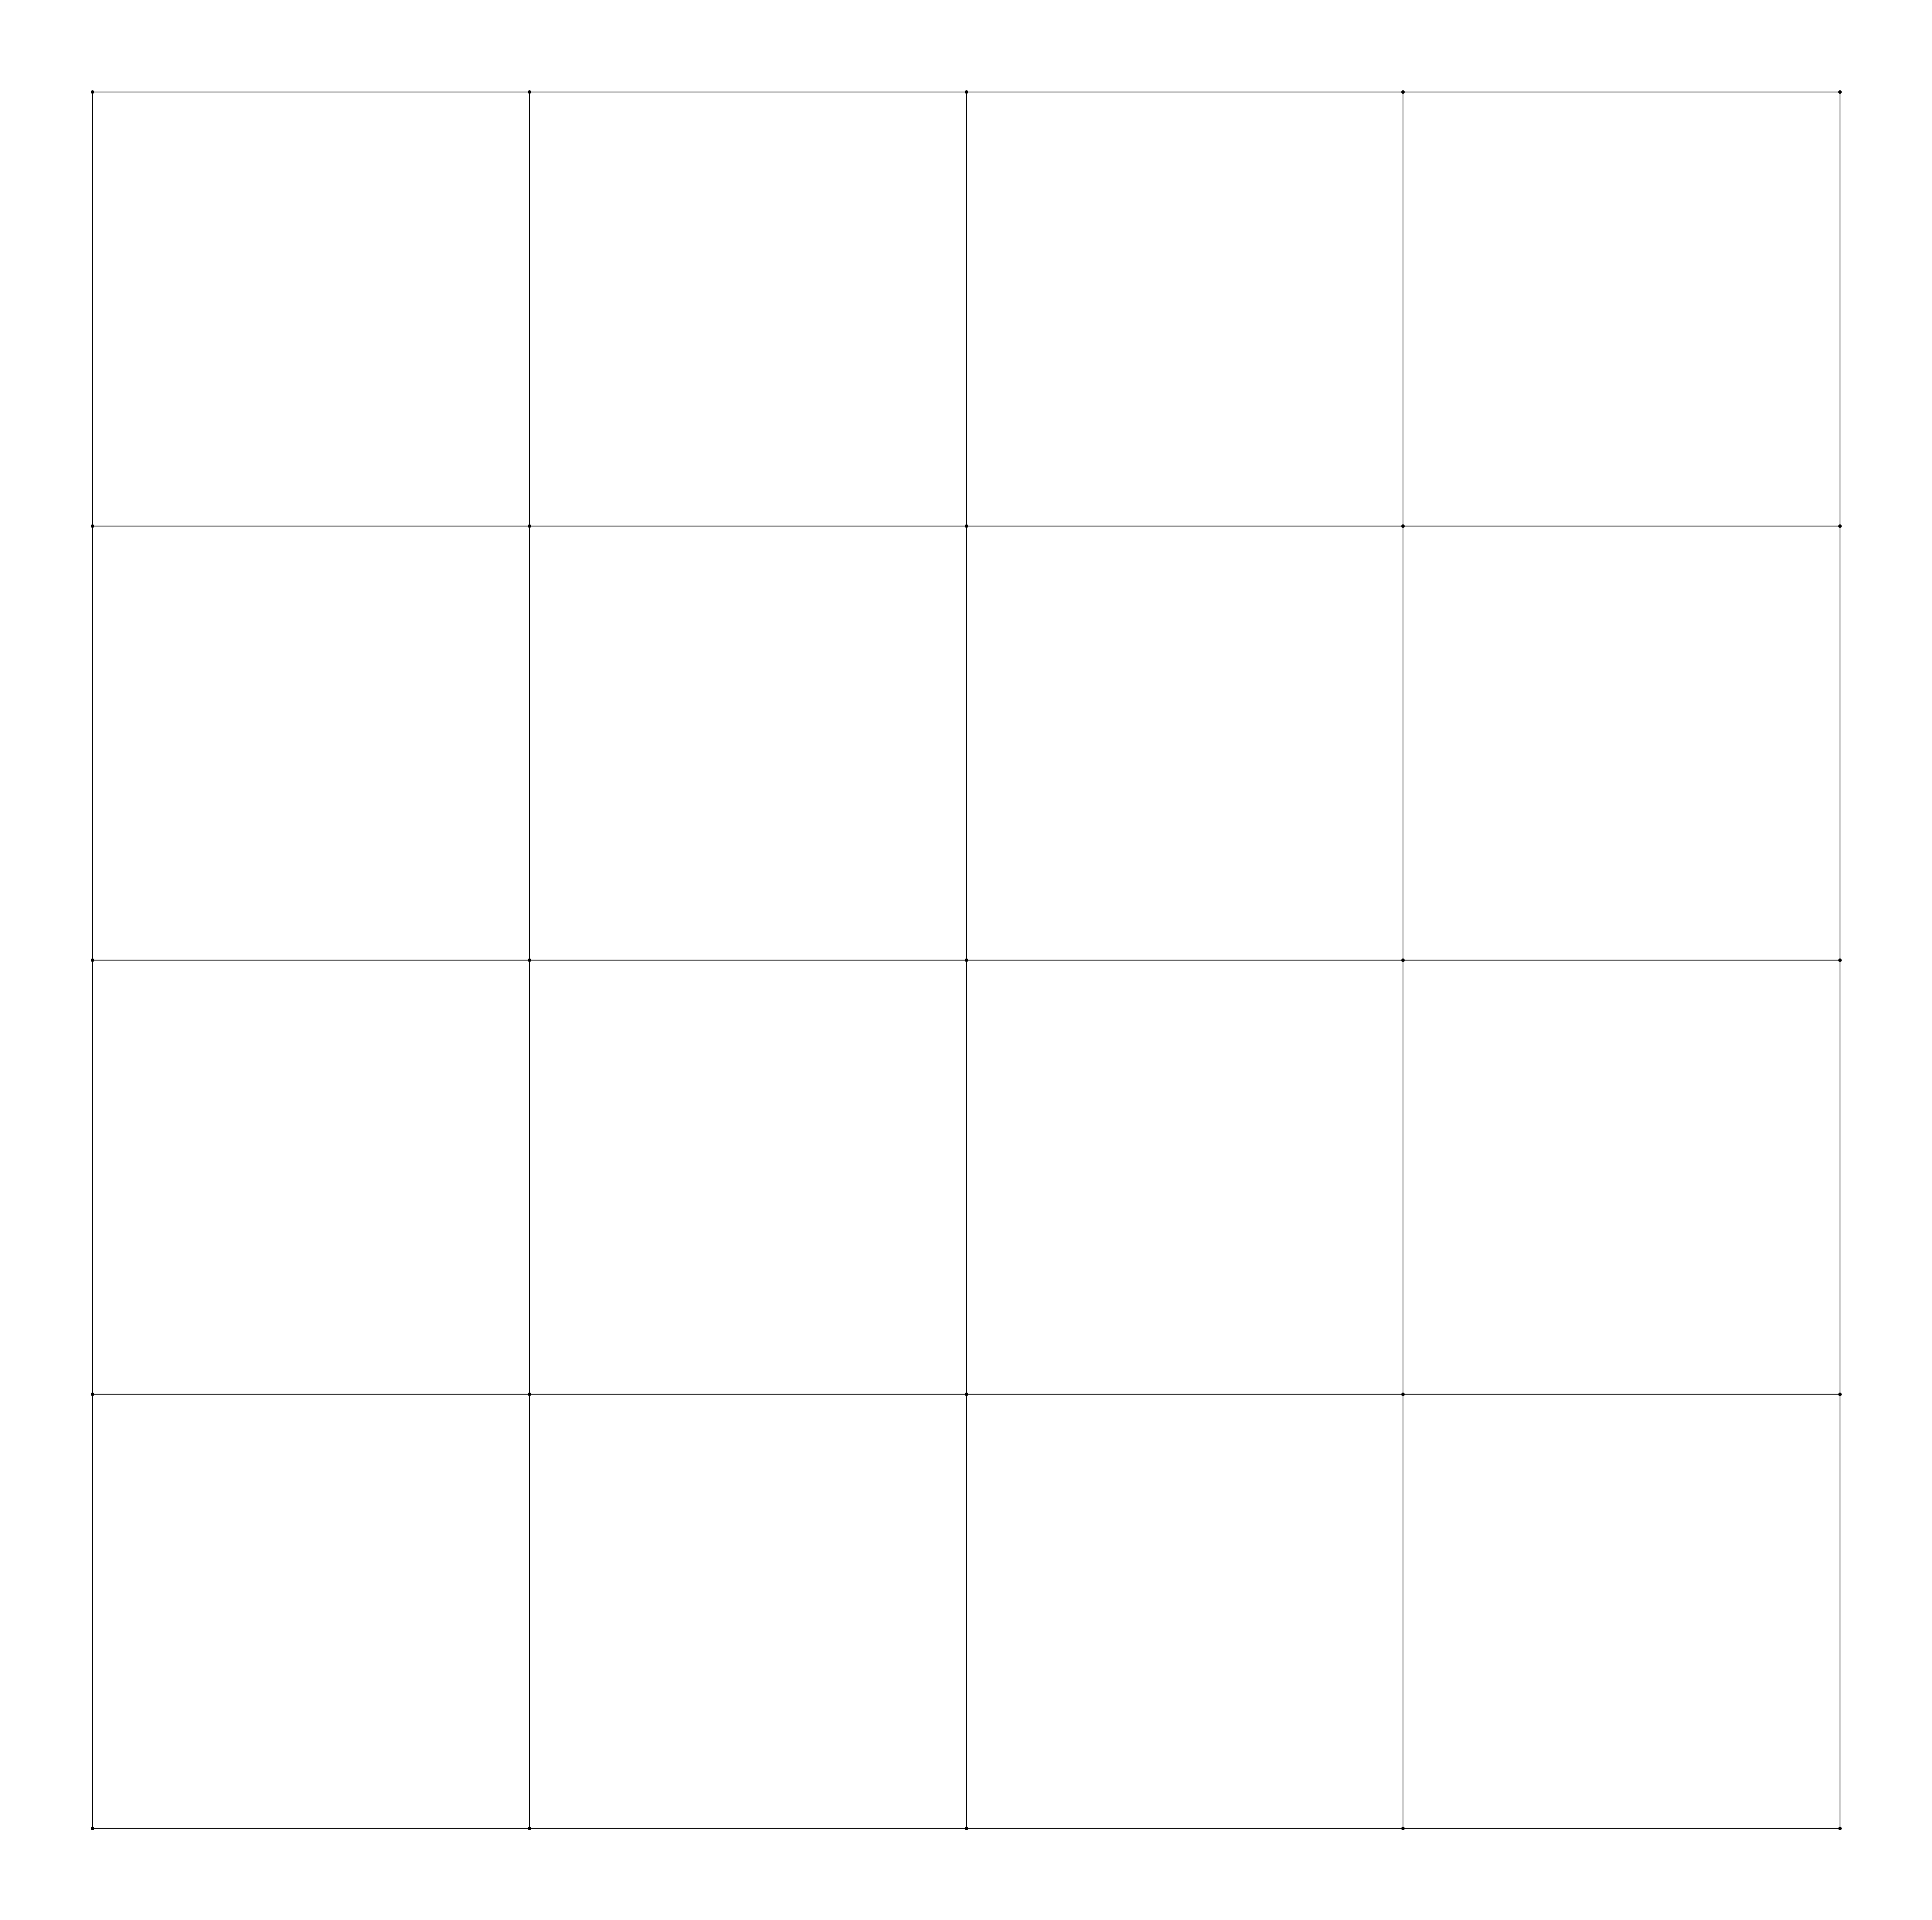

In [ ]:
from qunoc.utils.utils import get_timestamp
from qunoc.layout.env import QuNoCEnv
from qunoc.layout.agent import LayoutAgent

result_dir = f"result/layout/rl/example_{get_timestamp()}/"
os.makedirs(result_dir, exist_ok=True)

env = QuNoCEnv(result_dir=result_dir)
# env = QuNoCEnv((50, 50), FabricateModel(10, 10), result_dir=result_dir)
agent = LayoutAgent(env)
agent.train()
agent.save(f"{result_dir}/layout_agent.pth")
package = agent.design()
print("Package score: ", package.estimate_efficiency())
package.draw_qubits(save_path=f"{result_dir}/qubit_topology.png")
package.draw_chiplets(save_path=f"{result_dir}/chiplet_topology.png")